In [1]:
import sys
from pathlib import Path
import importlib

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

import seaborn as sns

ROOT = Path.cwd()

FITS_DIR = ROOT / "fits_files"
FIGS_DIR = ROOT / "figures"
FIGS_DIR.mkdir(exist_ok=True)

sys.path.insert(0, str(ROOT))
sys.path.insert(0, str(ROOT / "py_modules"))

import results_comp
import fit_fraction_latex_tools as ffa

ffa = importlib.reload(ffa)

sns.set_context("talk")


Configuration

In [2]:
ALL_FIT_LIMITS = (
    0.2,
    0.3,
    0.4,
    0.5,
    0.6,
    0.7,
    0.8,
    0.9,
    1.0
)

In [3]:
DATASET_CONFIGS = [
    {
        "group": "MUSE",
        "dataset_prefix": "MUSE-30Dor",
        "bin_levels": (0,),
        "line_order": ("H",),
        "filename_template":
            "{dataset_prefix}-{file_line}-bin{bin}_{fit_tag}",
    },

    {
        "group": "SAMFP",
        "dataset_prefix": "SAMFP-30Dor",
        "bin_levels": (0,),
        "line_order": ("H",),

        # Internal key H, but filename uses Ha
        "file_line_ids": {
            "H": "Ha",
        },

        "filename_template":
            "{dataset_prefix}-{file_line}-bin{bin}_{fit_tag}",
    },
]

Preview the expected files

In [4]:
samples = ffa.build_fraction_sample_grid(
    DATASET_CONFIGS,
    ALL_FIT_LIMITS,
)

sample_table = pd.DataFrame(samples)[
    ["group", "bin", "line", "fit_limit", "file_name"]
]

display(sample_table)

,group,bin,line,fit_limit,file_name
0,MUSE,0,H,0.2,MUSE-30Dor-H-bin0_02
1,MUSE,0,H,0.3,MUSE-30Dor-H-bin0_03
2,MUSE,0,H,0.4,MUSE-30Dor-H-bin0_04
3,MUSE,0,H,0.5,MUSE-30Dor-H-bin0_05
4,MUSE,0,H,0.6,MUSE-30Dor-H-bin0_06
5,MUSE,0,H,0.7,MUSE-30Dor-H-bin0_07
6,MUSE,0,H,0.8,MUSE-30Dor-H-bin0_08
7,MUSE,0,H,0.9,MUSE-30Dor-H-bin0_09
8,MUSE,0,H,1.0,MUSE-30Dor-H-bin0_10
9,SAMFP,0,H,0.2,SAMFP-30Dor-Ha-bin0_02


Load the complete \(L_{\rm frac}\)

In [5]:
all_fraction_results, failures = (
    ffa.load_multi_line_bin_fraction_results(
        results_comp,
        FITS_DIR,
        dataset_configs=DATASET_CONFIGS,
        fit_limits=ALL_FIT_LIMITS,
        read_header=True,
        on_error="warn",
        return_failures=True,
    )
)

print(f"Loaded: {len(all_fraction_results)}")
print(f"Unavailable: {len(failures)}")

if failures:
    display(
        pd.DataFrame(failures)[
            ["file_name", "error"]
        ]
    )

Loaded: 18
Unavailable: 0


Convert the complete sample to a tidy table

In [6]:
fraction_table = ffa.results_to_dataframe(
    all_fraction_results
)

display(fraction_table)

,group,bin,line,fit_limit,fit_limits_used,selection_mode,parameter,value,err_lower,err_upper,lower_limit,upper_limit,n_samples
0,MUSE,0,H,0.2,None,None,sig2,210.543238,17.264807,55.109408,193.278431,265.652646,None
1,MUSE,0,H,0.2,None,None,r0,2.276951,0.252627,0.948468,2.024325,3.225420,None
2,MUSE,0,H,0.2,None,None,m,1.068738,0.144998,0.068789,0.923740,1.137527,None
3,MUSE,0,H,0.2,None,None,noise,5.104529,0.589824,0.592156,4.514705,5.696685,None
4,MUSE,0,H,0.2,None,None,s0,0.079662,0.021701,0.043032,0.057960,0.122693,None
...,...,...,...,...,...,...,...,...,...,...,...,...,...
85,SAMFP,0,H,1.0,None,None,sig2,1733.146456,494.363125,14.384649,1238.783332,1747.531106,None
86,SAMFP,0,H,1.0,None,None,r0,60.474651,22.921447,-0.285325,37.553204,60.189326,None
87,SAMFP,0,H,1.0,None,None,m,0.841608,0.010673,0.025778,0.830934,0.867386,None
88,SAMFP,0,H,1.0,None,None,noise,5.022326,0.465734,0.427464,4.556592,5.449790,None


Section 3 — inspect the complete \(L_{\rm frac}\) sample

In [7]:
PARAMETERS = ("sig2", "r0", "m", "noise", "s0")

PARAM_LABELS = {
    "sig2": r"$\sigma^2$ [km$^2$ s$^{-2}$]",
    "r0": r"$r_0$ [pc]",
    "m": r"$m$",
    "noise": r"$B_\mathrm{noise}$ [km$^2$ s$^{-2}$]",
    "s0": r"$s_0$ [pc]",
}

PARAM_TITLES = {
    "sig2": r"$\sigma^2$",
    "r0": r"$r_0$",
    "m": r"$m$",
    "noise": r"$B_\mathrm{noise}$",
    "s0": r"$s_0$",
}

MUSE — sig2: negative lower uncertainty at Lfrac = [0.6] -> lower limit set to zero
MUSE — r0: negative lower uncertainty at Lfrac = [0.6] -> lower limit set to zero


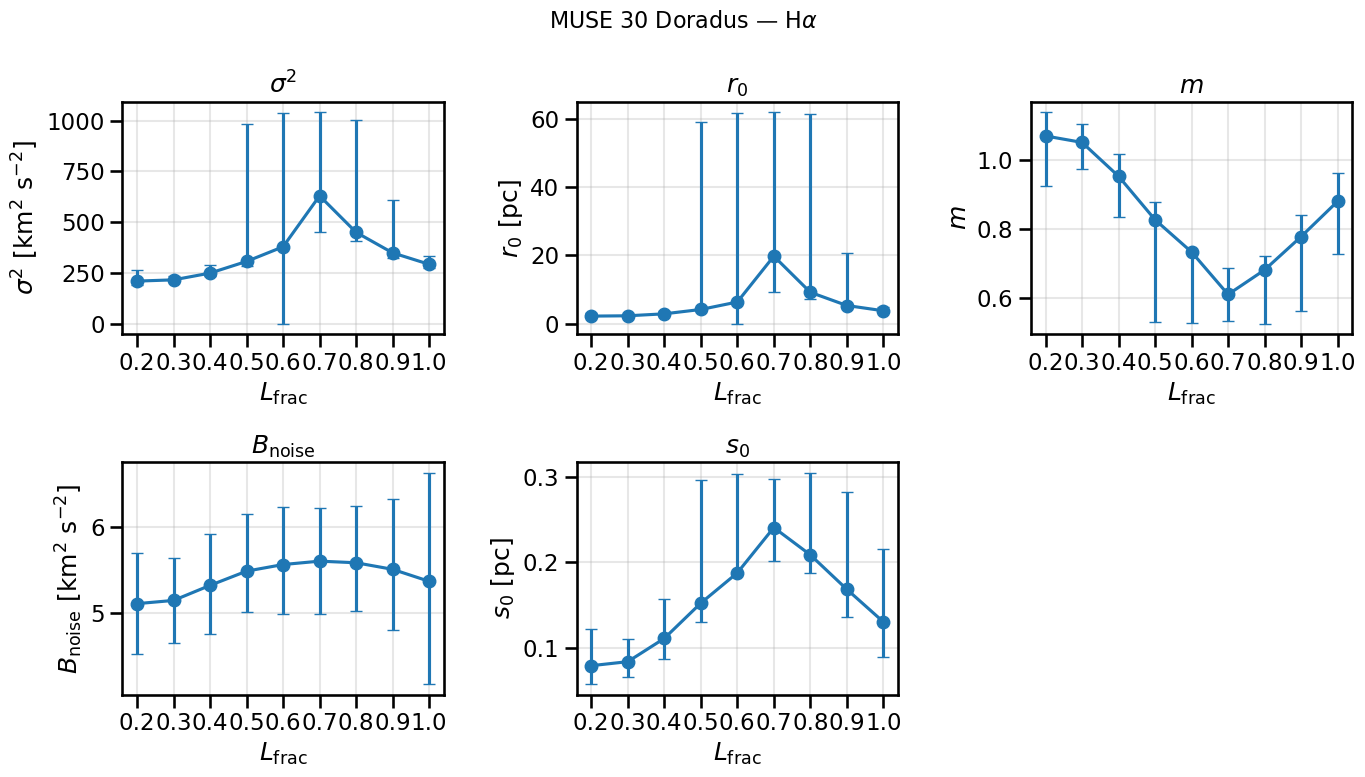

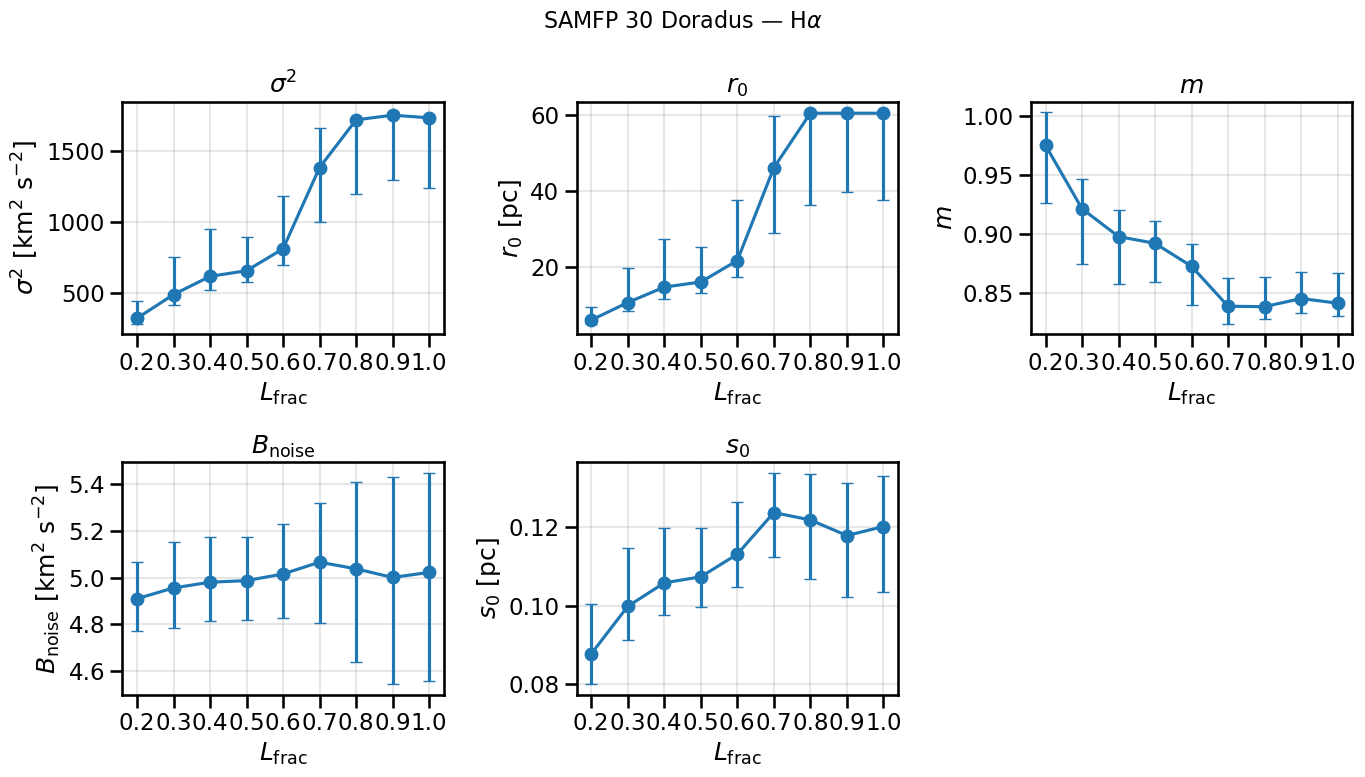

In [8]:
GROUPS_TO_PLOT = tuple(
    dict.fromkeys(fraction_table["group"])
)

for group in GROUPS_TO_PLOT:

    fig, axes = plt.subplots(
        2, 3,
        figsize=(14, 8),
    )

    axes = axes.ravel()

    # Fit limits actually available for this instrument
    group_fit_limits = tuple(
        sorted(
            fraction_table.loc[
                fraction_table["group"] == group,
                "fit_limit",
            ].unique()
        )
    )

    for ax, param in zip(axes, PARAMETERS):

        df_param = (
            fraction_table[
                (fraction_table["parameter"] == param)
                &
                (fraction_table["group"] == group)
            ]
            .sort_values("fit_limit")
        )

        x = df_param["fit_limit"].to_numpy()
        y = df_param["value"].to_numpy(dtype=float)

        err_lower = df_param["err_lower"].to_numpy(dtype=float)
        err_upper = df_param["err_upper"].to_numpy(dtype=float)

        # --------------------------------------------------
        # Lower uncertainty
        #
        # If the stored lower uncertainty is negative,
        # interpret it as reaching the physical boundary
        # at zero. Therefore the lower error magnitude
        # becomes equal to the central value.
        # --------------------------------------------------
        bad_lower = err_lower < 0

        if np.any(bad_lower):
            print(
                f"{group} — {param}: negative lower uncertainty "
                f"at Lfrac = "
                f"{df_param.loc[bad_lower, 'fit_limit'].tolist()} "
                "-> lower limit set to zero"
            )

        err_lower_plot = np.where(
            bad_lower,
            y,
            np.abs(err_lower),
        )

        # Upper errors must be positive magnitudes
        err_upper_plot = np.abs(err_upper)

        yerr = np.vstack([
            err_lower_plot,
            err_upper_plot,
        ])

        # --------------------------------------------------
        # Plot
        # --------------------------------------------------
        ax.errorbar(
            x,
            y,
            yerr=yerr,
            marker="o",
            linestyle="-",
            capsize=4,
            label="Individual fits",
        )

        ax.set_title(
            PARAM_TITLES[param]
        )

        ax.set_xlabel(
            r"$L_{\rm frac}$"
        )

        ax.set_ylabel(
            PARAM_LABELS[param]
        )

        ax.set_xticks(
            group_fit_limits
        )

        ax.grid(
            alpha=0.3
        )

    # --------------------------------------------------
    # Empty panel
    # --------------------------------------------------
    axes[-1].axis("off")

    # --------------------------------------------------
    # Figure title
    # --------------------------------------------------
    fig.suptitle(
        rf"{group} 30 Doradus — H$\alpha$",
        fontsize=16,
    )

    fig.tight_layout()

    plt.show()

Visually indicate the fractions selected for the final result

In [9]:
SELECTED_FIT_LIMITS = (0.2, 0.3, 0.4)

In [10]:
FIT_LIMITS_BY_GROUP = {
    "MUSE": (
        0.2,
        0.3,
        0.4,
    ),

    "SAMFP": (
        0.2,
        0.3,
        0.4,
    ),
}

In [11]:
# Selected fit limits for this instrument
selected_fit_limits = FIT_LIMITS_BY_GROUP[group]

selected_min = min(selected_fit_limits)
selected_max = max(selected_fit_limits)

# Highlight adopted Lfrac interval
ax.axvspan(
    selected_min,
    selected_max,
    alpha=0.10,
)

# Identify the individual fits used in the adopted result
selected_mask = df_param["fit_limit"].isin(
    selected_fit_limits
)

ax.scatter(
    df_param.loc[selected_mask, "fit_limit"],
    df_param.loc[selected_mask, "value"],
    s=90,
    facecolors="none",
    edgecolors="black",
    linewidths=1.5,
    zorder=5,
)

Downstream selection and averaging

In [12]:
selected_results_pc = (
    ffa.select_or_average_fit_results(
        all_fraction_results,
        fit_limits_by_group=FIT_LIMITS_BY_GROUP,
        group_keys=("group", "bin", "line"),
    )
)

selected_table_pc = ffa.results_to_dataframe(
    selected_results_pc
)

display(selected_table_pc)

,group,bin,line,fit_limit,fit_limits_used,selection_mode,parameter,value,err_lower,err_upper,lower_limit,upper_limit,n_samples
0,MUSE,0,H,None,"(0.2, 0.3, 0.4)",average,sig2,225.710123,32.431691,65.061026,193.278431,290.771149,3
1,MUSE,0,H,None,"(0.2, 0.3, 0.4)",average,r0,2.529723,0.505398,1.287584,2.024325,3.817306,3
2,MUSE,0,H,None,"(0.2, 0.3, 0.4)",average,m,1.023771,0.189899,0.113757,0.833872,1.137527,3
3,MUSE,0,H,None,"(0.2, 0.3, 0.4)",average,noise,5.188290,0.673585,0.731041,4.514705,5.919331,3
4,MUSE,0,H,None,"(0.2, 0.3, 0.4)",average,s0,0.091828,0.033868,0.065546,0.057960,0.157374,3
5,SAMFP,0,H,None,"(0.2, 0.3, 0.4)",average,sig2,474.568099,194.099003,474.048867,280.469097,948.616966,3
6,SAMFP,0,H,None,"(0.2, 0.3, 0.4)",average,r0,10.409485,5.446930,16.797467,4.962555,27.206951,3
7,SAMFP,0,H,None,"(0.2, 0.3, 0.4)",average,m,0.931556,0.073537,0.071768,0.858019,1.003324,3
8,SAMFP,0,H,None,"(0.2, 0.3, 0.4)",average,noise,4.948696,0.178929,0.224471,4.769766,5.173167,3
9,SAMFP,0,H,None,"(0.2, 0.3, 0.4)",average,s0,0.097802,0.017865,0.022003,0.079937,0.119804,3


In [13]:
PARAMETERS = ("sig2", "r0", "m", "noise", "s0")

PARAM_LABELS = {
    "sig2": r"$\sigma^2$ [km$^2$ s$^{-2}$]",
    "r0": r"$r_0$ [pc]",
    "m": r"$m$",
    "noise": r"$B_\mathrm{noise}$ [km$^2$ s$^{-2}$]",
    "s0": r"$s_0$ [pc]",
}

PARAM_TITLES = {
    "sig2": r"$\sigma^2$",
    "r0": r"$r_0$",
    "m": r"$m$",
    "noise": r"$B_\mathrm{noise}$",
    "s0": r"$s_0$",
}

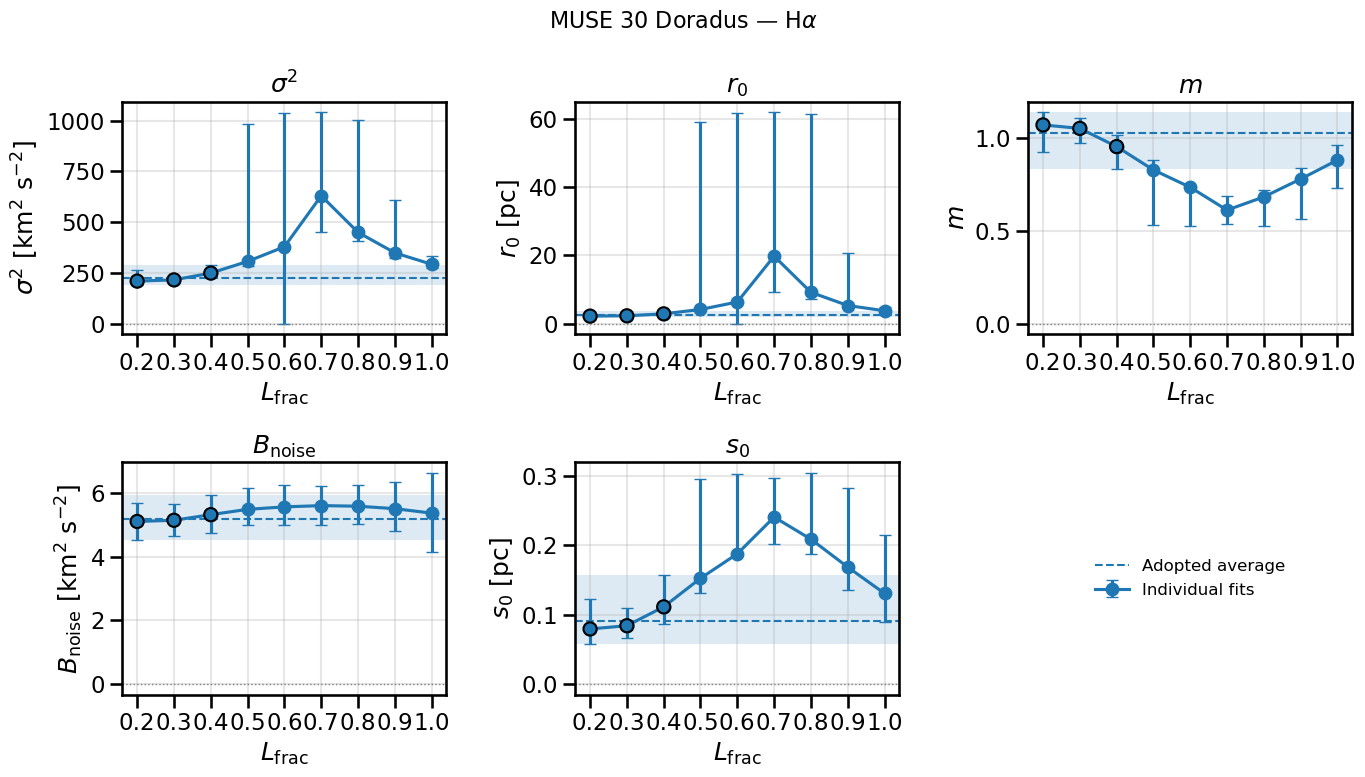

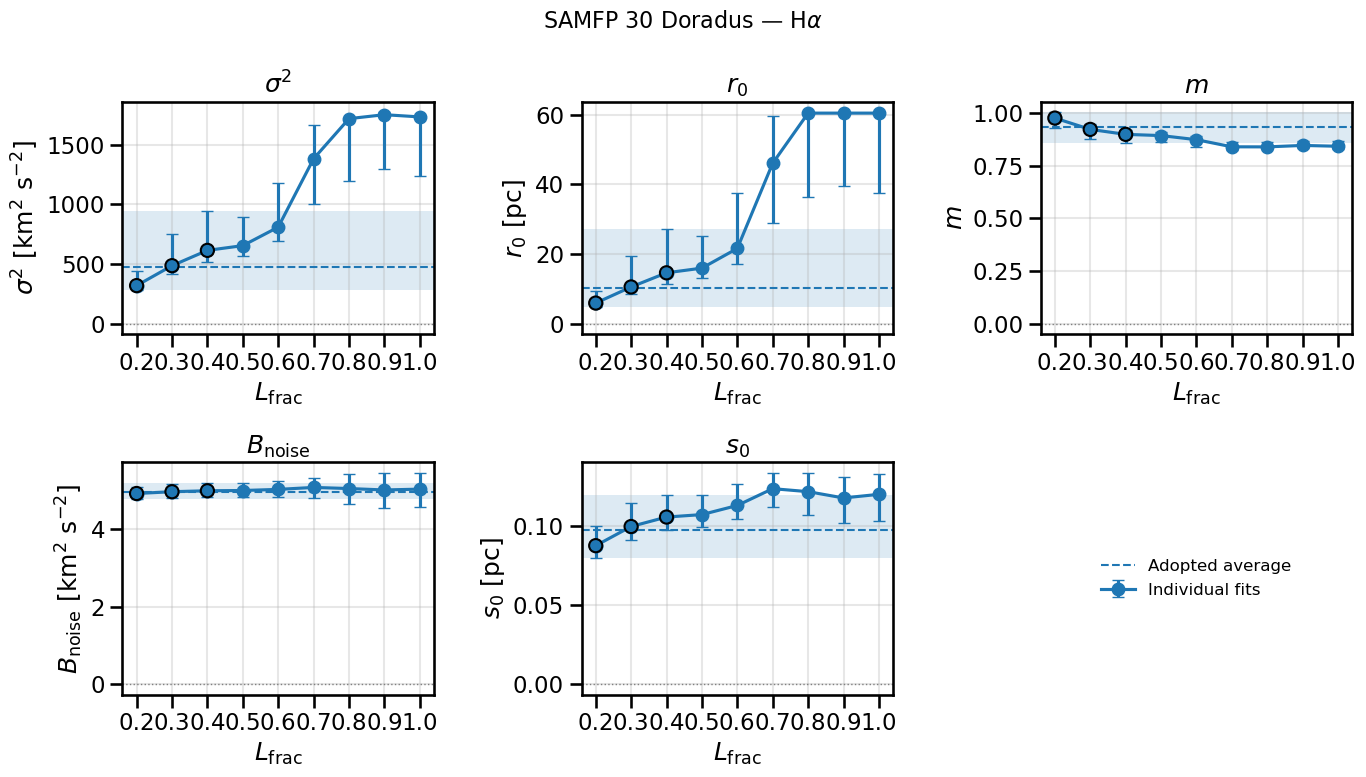

In [14]:
GROUPS_TO_PLOT = tuple(
    dict.fromkeys(fraction_table["group"])
)

for group in GROUPS_TO_PLOT:

    fig, axes = plt.subplots(
        2, 3,
        figsize=(14, 8),
    )

    axes = axes.ravel()

    # Selected Lfrac values for this instrument
    selected_fit_limits = FIT_LIMITS_BY_GROUP[group]

    # Fit limits available for this instrument
    group_fit_limits = tuple(
        sorted(
            fraction_table.loc[
                fraction_table["group"] == group,
                "fit_limit",
            ].unique()
        )
    )

    for ax, param in zip(axes, PARAMETERS):

        # --------------------------------------------------
        # Complete Lfrac sample for this instrument
        # --------------------------------------------------
        df_raw = (
            fraction_table[
                (fraction_table["parameter"] == param)
                &
                (fraction_table["group"] == group)
            ]
            .sort_values("fit_limit")
        )

        x = df_raw["fit_limit"].to_numpy()
        y = df_raw["value"].to_numpy(dtype=float)

        err_lower = df_raw["err_lower"].to_numpy(dtype=float)
        err_upper = df_raw["err_upper"].to_numpy(dtype=float)

        # --------------------------------------------------
        # Error-bar treatment
        #
        # Negative lower uncertainties are interpreted as
        # extending to the physical boundary at zero.
        # --------------------------------------------------
        bad_lower = err_lower < 0

        err_lower_plot = np.where(
            bad_lower,
            y,
            np.abs(err_lower),
        )

        err_upper_plot = np.abs(
            err_upper
        )

        yerr = np.vstack([
            err_lower_plot,
            err_upper_plot,
        ])

        ax.errorbar(
            x,
            y,
            yerr=yerr,
            marker="o",
            linestyle="-",
            capsize=4,
            label="Individual fits",
        )

        # --------------------------------------------------
        # Selected / averaged result for this instrument
        # --------------------------------------------------
        df_avg = selected_table_pc[
            (selected_table_pc["parameter"] == param)
            &
            (selected_table_pc["group"] == group)
        ]

        if len(df_avg) == 1:

            avg = float(
                df_avg["value"].iloc[0]
            )

            avg_lower = float(
                df_avg["err_lower"].iloc[0]
            )

            avg_upper = float(
                df_avg["err_upper"].iloc[0]
            )

            # Same convention for a negative
            # lower uncertainty
            if avg_lower < 0:
                lower_limit = 0.0
            else:
                lower_limit = avg - abs(avg_lower)

            upper_limit = (
                avg + abs(avg_upper)
            )

            # Mean adopted value
            ax.axhline(
                avg,
                linestyle="--",
                linewidth=1.5,
                label="Adopted average",
            )

            # Full uncertainty envelope
            ax.axhspan(
                lower_limit,
                upper_limit,
                alpha=0.15,
            )

        # --------------------------------------------------
        # Mark selected Lfrac values
        # --------------------------------------------------
        selected_mask = (
            df_raw["fit_limit"]
            .isin(selected_fit_limits)
        )

        ax.scatter(
            df_raw.loc[
                selected_mask,
                "fit_limit",
            ],
            df_raw.loc[
                selected_mask,
                "value",
            ],
            s=90,
            facecolors="none",
            edgecolors="black",
            linewidths=1.5,
            zorder=5,
        )

        # --------------------------------------------------
        # Reference line
        # --------------------------------------------------
        ax.axhline(
            0.0,
            color="0.5",
            linestyle=":",
            linewidth=1.0,
        )

        # --------------------------------------------------
        # Axes
        # --------------------------------------------------
        ax.set_title(
            PARAM_TITLES[param]
        )

        ax.set_xlabel(
            r"$L_{\rm frac}$"
        )

        ax.set_ylabel(
            PARAM_LABELS[param]
        )

        ax.set_xticks(
            group_fit_limits
        )

        ax.grid(
            alpha=0.3
        )

    # --------------------------------------------------
    # Legend in empty panel
    # --------------------------------------------------
    axes[-1].axis("off")

    handles, labels = (
        axes[0].get_legend_handles_labels()
    )

    axes[-1].legend(
        handles,
        labels,
        loc="center",
        frameon=False,
        fontsize=12,
    )

    # --------------------------------------------------
    # Figure title
    # --------------------------------------------------
    fig.suptitle(
        rf"{group} 30 Doradus — H$\alpha$",
        fontsize=16,
    )

    fig.tight_layout()

    # --------------------------------------------------
    # Save
    # --------------------------------------------------
    fig.savefig(
        FIGS_DIR
        / f"{group}_30Dor_H_Lfrac_diagnostics.jpg",
        dpi=300,
        bbox_inches="tight",
    )

    plt.show()

In [15]:
adopted_table = (
    selected_table_pc[
        ["parameter", "value", "err_lower", "err_upper"]
    ]
    .copy()
)

display(adopted_table)

,parameter,value,err_lower,err_upper
0,sig2,225.710123,32.431691,65.061026
1,r0,2.529723,0.505398,1.287584
2,m,1.023771,0.189899,0.113757
3,noise,5.188290,0.673585,0.731041
4,s0,0.091828,0.033868,0.065546
5,sig2,474.568099,194.099003,474.048867
6,r0,10.409485,5.446930,16.797467
7,m,0.931556,0.073537,0.071768
8,noise,4.948696,0.178929,0.224471
9,s0,0.097802,0.017865,0.022003


In [16]:
selected_results = ffa.convert_s0_pc_to_arcsec(
    selected_results_pc,
    fwhm_factor=2.355,
    copy=True,
)

selected_table = ffa.results_to_dataframe(
    selected_results
)

display(selected_table)

,group,bin,line,fit_limit,fit_limits_used,selection_mode,parameter,value,err_lower,err_upper,lower_limit,upper_limit,n_samples
0,MUSE,0,H,None,"(0.2, 0.3, 0.4)",average,sig2,225.710123,32.431691,65.061026,193.278431,290.771149,3
1,MUSE,0,H,None,"(0.2, 0.3, 0.4)",average,r0,2.529723,0.505398,1.287584,2.024325,3.817306,3
2,MUSE,0,H,None,"(0.2, 0.3, 0.4)",average,m,1.023771,0.189899,0.113757,0.833872,1.137527,3
3,MUSE,0,H,None,"(0.2, 0.3, 0.4)",average,noise,5.188290,0.673585,0.731041,4.514705,5.919331,3
4,MUSE,0,H,None,"(0.2, 0.3, 0.4)",average,s0,0.892114,0.329026,0.636786,0.563088,1.528900,3
5,SAMFP,0,H,None,"(0.2, 0.3, 0.4)",average,sig2,474.568099,194.099003,474.048867,280.469097,948.616966,3
6,SAMFP,0,H,None,"(0.2, 0.3, 0.4)",average,r0,10.409485,5.446930,16.797467,4.962555,27.206951,3
7,SAMFP,0,H,None,"(0.2, 0.3, 0.4)",average,m,0.931556,0.073537,0.071768,0.858019,1.003324,3
8,SAMFP,0,H,None,"(0.2, 0.3, 0.4)",average,noise,4.948696,0.178929,0.224471,4.769766,5.173167,3
9,SAMFP,0,H,None,"(0.2, 0.3, 0.4)",average,s0,0.950149,0.173559,0.213760,0.776590,1.163909,3


In [17]:
PARAMETERS = ("sig2", "r0", "m", "noise", "s0")

PARAM_LABELS_FINAL = {
    "sig2": r"$\sigma^2$ [km$^2$ s$^{-2}$]",
    "r0": r"$r_0$ [pc]",
    "m": r"$m$",
    "noise": r"$B_\mathrm{noise}$ [km$^2$ s$^{-2}$]",
    "s0": r"$s_0$ [arcsec]",
}

PARAM_TITLES = {
    "sig2": r"$\sigma^2$",
    "r0": r"$r_0$",
    "m": r"$m$",
    "noise": r"$B_\mathrm{noise}$",
    "s0": r"$s_0$",
}

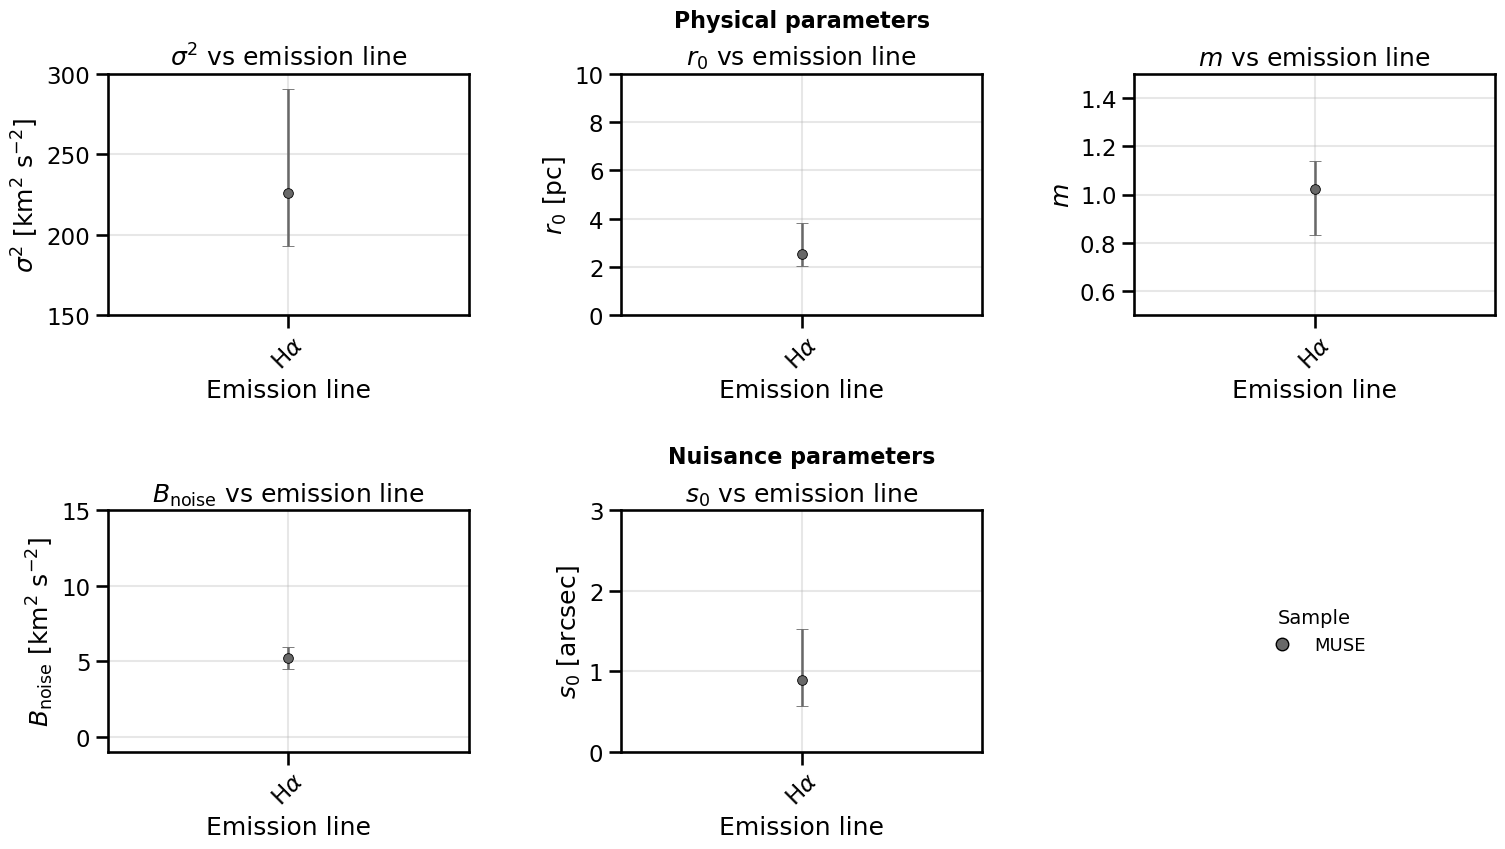

In [18]:
sample_selected = selected_results

LINE_LABELS = {
    "H": r"H$\alpha$",
}

PARAM_LABELS_ARCSEC = {
    "sig2": r"$\sigma^2$ [km$^2$ s$^{-2}$]",
    "r0": r"$r_0$ [pc]",
    "m": r"$m$",
    "noise": r"$B_\mathrm{noise}$ [km$^2$ s$^{-2}$]",
    "s0": r"$s_0$ [arcsec]",
}

fig_samples, axes_samples = ffa.plot_param_grid_lines_as_x(
    sample_selected,

    line_order=("H",),

    group_order=("MUSE",),
    group_key="group",

    line_labels=LINE_LABELS,
    param_labels=PARAM_LABELS_ARCSEC,

    param_ylims={
        "sig2": (150, 300),
        "r0": (0, 10),
        "m": (0.5, 1.5),
        "noise": (-1, 15),
        "s0": (0, 3),
    },

    row_titles=(
        "Physical parameters",
        "Nuisance parameters",
    ),

    row_title_fontsize=16,
    figsize=(15, 9),

    jitter=0.10,

    save=True,
    savepath=FIGS_DIR / "fit_fraction_average_by_sample.pdf",
)

for ax in axes_samples[:5]:
    ax.set_box_aspect(None)
    ax.set_aspect("auto")

fig_samples.subplots_adjust(
    left=0.065,
    right=0.99,
    wspace=0.42,
)

plt.show()

Groups: ('MUSE', 'SAMFP')


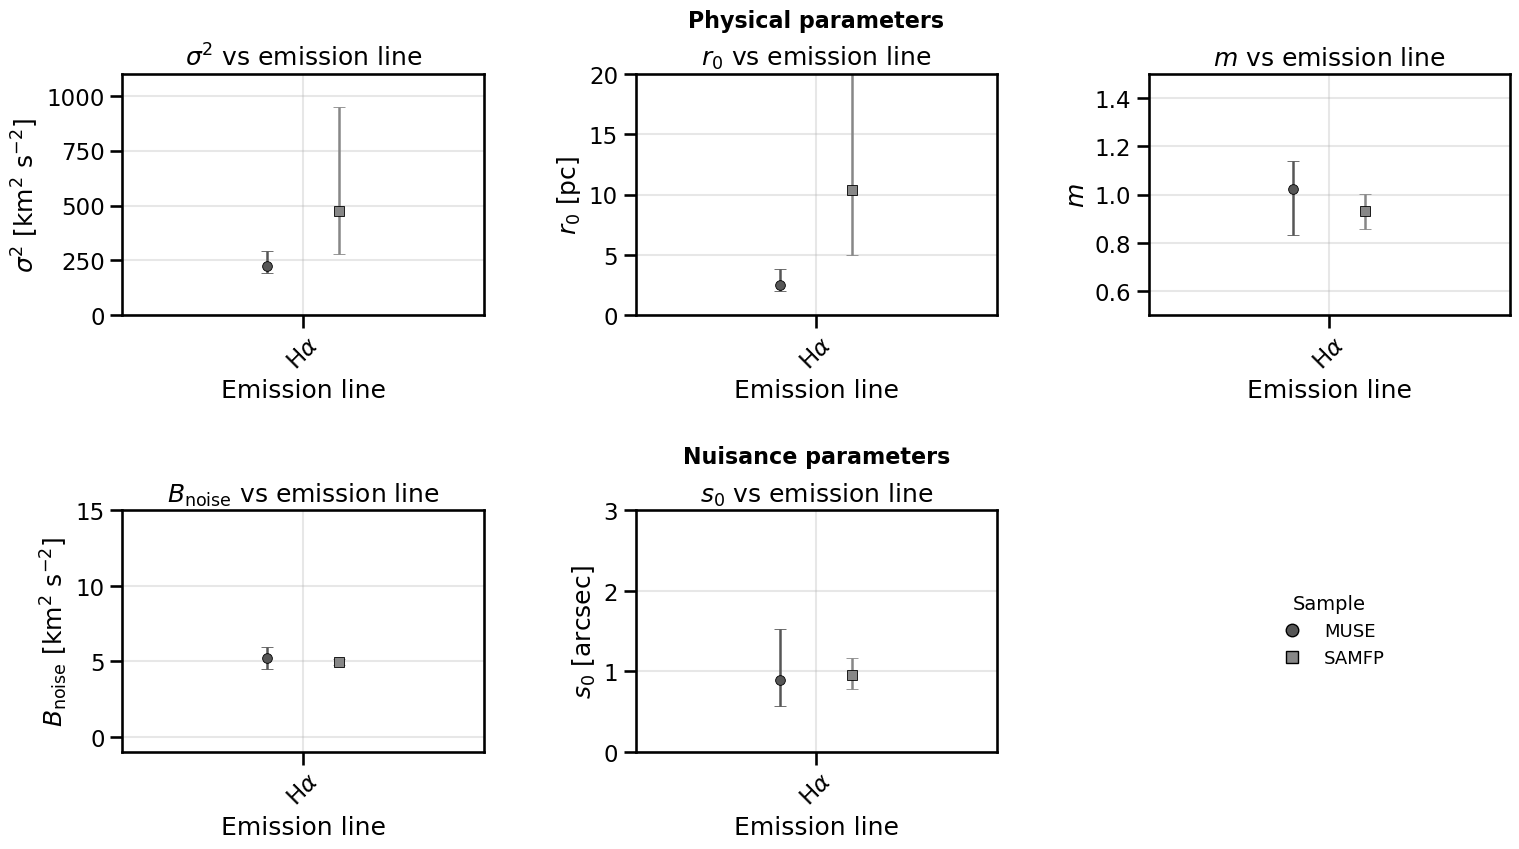

In [19]:
sample_selected = selected_results

# --------------------------------------------------
# Labels
# --------------------------------------------------

LINE_LABELS = {
    "H": r"H$\alpha$",
}

PARAM_LABELS_ARCSEC = {
    "sig2": r"$\sigma^2$ [km$^2$ s$^{-2}$]",
    "r0": r"$r_0$ [pc]",
    "m": r"$m$",
    "noise": r"$B_\mathrm{noise}$ [km$^2$ s$^{-2}$]",
    "s0": r"$s_0$ [arcsec]",
}


# --------------------------------------------------
# Instrument order
#
# Automatically obtained from the selected sample.
# Current result:
# ("MUSE", "SAMFP")
# --------------------------------------------------

GROUP_ORDER = tuple(
    dict.fromkeys(
        entry["group"]
        for entry in sample_selected
    )
)

print("Groups:", GROUP_ORDER)


# --------------------------------------------------
# Plot adopted results
# --------------------------------------------------

fig_samples, axes_samples = ffa.plot_param_grid_lines_as_x(
    sample_selected,

    line_order=("H",),

    group_order=GROUP_ORDER,
    group_key="group",

    line_labels=LINE_LABELS,
    param_labels=PARAM_LABELS_ARCSEC,

    param_ylims={
        "sig2": (0, 1100),
        "r0": (0, 20),
        "m": (0.5, 1.5),
        "noise": (-1, 15),
        "s0": (0, 3),
    },

    row_titles=(
        "Physical parameters",
        "Nuisance parameters",
    ),

    row_title_fontsize=16,
    figsize=(15, 9),

    jitter=0.10,

    save=True,
    savepath=FIGS_DIR / "fit_fraction_average_by_sample.pdf",
)


# --------------------------------------------------
# Panel formatting
# --------------------------------------------------

for ax in axes_samples[:5]:
    ax.set_box_aspect(None)
    ax.set_aspect("auto")


fig_samples.subplots_adjust(
    left=0.065,
    right=0.99,
    wspace=0.42,
)

plt.show()

In [20]:
adopted_summary = (
    selected_table[
        [
            "group",
            "line",
            "fit_limits_used",
            "parameter",
            "value",
            "err_lower",
            "err_upper",
        ]
    ]
    .copy()
)

display(adopted_summary)

,group,line,fit_limits_used,parameter,value,err_lower,err_upper
0,MUSE,H,"(0.2, 0.3, 0.4)",sig2,225.710123,32.431691,65.061026
1,MUSE,H,"(0.2, 0.3, 0.4)",r0,2.529723,0.505398,1.287584
2,MUSE,H,"(0.2, 0.3, 0.4)",m,1.023771,0.189899,0.113757
3,MUSE,H,"(0.2, 0.3, 0.4)",noise,5.188290,0.673585,0.731041
4,MUSE,H,"(0.2, 0.3, 0.4)",s0,0.892114,0.329026,0.636786
5,SAMFP,H,"(0.2, 0.3, 0.4)",sig2,474.568099,194.099003,474.048867
6,SAMFP,H,"(0.2, 0.3, 0.4)",r0,10.409485,5.446930,16.797467
7,SAMFP,H,"(0.2, 0.3, 0.4)",m,0.931556,0.073537,0.071768
8,SAMFP,H,"(0.2, 0.3, 0.4)",noise,4.948696,0.178929,0.224471
9,SAMFP,H,"(0.2, 0.3, 0.4)",s0,0.950149,0.173559,0.213760


Build the final adopted-parameter table

In [21]:
FINAL_PARAMETERS = ("sig2", "r0", "m", "noise", "s0")

# Automatically determine the available groups
GROUP_ORDER = tuple(
    dict.fromkeys(selected_table["group"])
)

final_rows = []

for group in GROUP_ORDER:

    df_group = selected_table[
        selected_table["group"] == group
    ]

    if df_group.empty:
        continue

    row = {
        "group": group,
        "line": df_group["line"].iloc[0],
        "fit_limits_used": df_group["fit_limits_used"].iloc[0],
    }

    for param in FINAL_PARAMETERS:

        df_param = df_group[
            df_group["parameter"] == param
        ]

        if df_param.empty:
            continue

        values = df_param.iloc[0]

        row[param] = values["value"]
        row[f"{param}_err_lower"] = values["err_lower"]
        row[f"{param}_err_upper"] = values["err_upper"]

    final_rows.append(row)

final_table = pd.DataFrame(final_rows)

display(final_table)

,group,line,fit_limits_used,sig2,sig2_err_lower,sig2_err_upper,r0,r0_err_lower,r0_err_upper,m,m_err_lower,m_err_upper,noise,noise_err_lower,noise_err_upper,s0,s0_err_lower,s0_err_upper
0,MUSE,H,"(0.2, 0.3, 0.4)",225.710123,32.431691,65.061026,2.529723,0.505398,1.287584,1.023771,0.189899,0.113757,5.188290,0.673585,0.731041,0.892114,0.329026,0.636786
1,SAMFP,H,"(0.2, 0.3, 0.4)",474.568099,194.099003,474.048867,10.409485,5.446930,16.797467,0.931556,0.073537,0.071768,4.948696,0.178929,0.224471,0.950149,0.173559,0.213760


In [22]:
LATEX_LINE = "H"
LATEX_BIN = 0

latex_rows = []

for group in GROUP_ORDER:

    result_pc = ffa.get_fit_result(
        selected_results_pc,
        group=group,
        bin_level=LATEX_BIN,
        line=LATEX_LINE,
    )

    row = ffa.format_fit_summary_row(
        result_pc,
        fwhm=2.355,
        include_identifiers=True,
        line_labels=LINE_LABELS,
        row_terminator=True,
    )

    latex_rows.append(row)

print("\n".join(latex_rows))

MUSE & 0 & H$\alpha$ & 0.2,0.3,0.4 & 225.71\PM{65.06}{32.43} & 2.530\PM{1.288}{0.505} & 1.02\PM{0.11}{0.19} & 5.188\PM{0.731}{0.674} & <1.53 & 9.33 & <0.0622 & 0.019 \\
SAMFP & 0 & H$\alpha$ & 0.2,0.3,0.4 & 474.57\PM{474.05}{194.10} & 10.409\PM{16.797}{5.447} & 0.93\PM{0.07}{0.07} & 4.949\PM{0.224}{0.179} & <1.16 & 13.85 & <0.0115 & 0.004 \\


In [23]:
for group in GROUP_ORDER:

    result_pc = ffa.get_fit_result(
        selected_results_pc,
        group=group,
        bin_level=0,
        line="H",
    )

    print(f"\n--- {group} ---")

    ffa.print_fit_summary_row(
        result_pc,
        fwhm=2.355,
        include_identifiers=True,
        line_labels=LINE_LABELS,
        row_terminator=True,
    )


--- MUSE ---
MUSE & 0 & H$\alpha$ & 0.2,0.3,0.4 & 225.71\PM{65.06}{32.43} & 2.530\PM{1.288}{0.505} & 1.02\PM{0.11}{0.19} & 5.188\PM{0.731}{0.674} & <1.53 & 9.33 & <0.0622 & 0.019 \\

--- SAMFP ---
SAMFP & 0 & H$\alpha$ & 0.2,0.3,0.4 & 474.57\PM{474.05}{194.10} & 10.409\PM{16.797}{5.447} & 0.93\PM{0.07}{0.07} & 4.949\PM{0.224}{0.179} & <1.16 & 13.85 & <0.0115 & 0.004 \\


Export the adopted sample

In [24]:
OUTPUT_TABLE = ROOT / "fit_fraction_selected_results.csv"

final_table.to_csv(
    OUTPUT_TABLE,
    index=False,
)

print(f"Saved table to {OUTPUT_TABLE}")

Saved table to C:\Users\javas\Dropbox\GitHub\VIENTO\structure_function_analysis\30dor\analysis_v1\fit_fraction_selected_results.csv
